# Attribution methods

Today, we will attempt to:

- Explain an (extremely simple) toy model with different attribution methods
- Learn how to mess with attribution methods (a bit)

In [1]:
import torch
import captum

from matplotlib import pyplot as plt

/home/dominik/MyStuff/tml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## A simple model

$$f(x_1, \; x_2, \; x_3)=3x_1-2x_2+5$$

Normally, you'd like to explain models calculating, uhhh, somewhat more ambitious functions than this. However, we are doing this for educational reasons, hence this.

In [2]:
class ToyModel(torch.nn.Module):
    def __init__(self):
        super(ToyModel, self).__init__()
        self.w = torch.tensor([3, -2, 0]).float()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x @ self.w + 5

inputs = torch.Tensor([1, 1, 100])

model = ToyModel()

model(inputs)

tensor(6.)

**Question**: (you can discuss it with your friend. or not): Let's say that you want to somehow "explain" this function by performing an attribution, by stressing which input was "important" for making a prediction. How would you attribute this as a human? (there's no universal answer).

**Sanity check**: If you don't know what an attribution is, please ask the course instructor to explain it to you :D. It's very important everyone understands what we are actually doing.

We'll see how common methods determine these attributions.

### Saliency

Basically, saliency is the simplest thing you could think of. Since we use gradients to adjust weights, we could use them to show us which parts of the input would need to be changed to "change the mind" of the model:

$$a_i=\left|\frac{\partial f(x)}{\partial x_i}\right|.$$

where $a_i$ is attribution for the $i$-th feature.

In [3]:
def attribute_with_saliency(model: torch.nn.Module, inputs: torch.Tensor) -> torch.Tensor:
    inputs = inputs.clone()
    inputs.requires_grad_(True) # So that the torch "knows" to calculate the gradients

    pred = model(inputs)
    pred.backward()

    gradients = inputs.grad

    return torch.abs(gradients)

attribute_with_saliency(model, inputs)

tensor([3., 2., 0.])

In [4]:
print(attribute_with_saliency(model, torch.Tensor([0, 0, 0])))
print(attribute_with_saliency(model, torch.Tensor([5, 5, 10000])))

tensor([3., 2., 0.])
tensor([3., 2., 0.])


**Sanity check**: Why doesn't the attribution change here based on the inputs? When would you expect this property? When would you _not_ expect to see it?

### Input × Gradient

You won't gonna believe this.

$$a_i=x_i\frac{\partial f(x)}{\partial x_i}.$$

In [5]:
def attribute_with_input_x_gradient(model: torch.nn.Module, inputs: torch.Tensor) -> torch.Tensor:
    inputs = inputs.clone()
    inputs.requires_grad_(True) # So that the torch "knows" to calculate the gradients

    pred = model(inputs)
    pred.backward()

    gradients = inputs.grad

    # TODO: Change a line here so that this does what it should
    attribution = None 

    return attribution

print(attribute_with_input_x_gradient(model, inputs))
print(attribute_with_input_x_gradient(model, torch.Tensor([0, 0, 0])))
print(attribute_with_input_x_gradient(model, torch.Tensor([5, 5, 10000])))


tensor([ 3., -2.,  0.], grad_fn=<MulBackward0>)
tensor([0., -0., 0.], grad_fn=<MulBackward0>)
tensor([ 15., -10.,   0.], grad_fn=<MulBackward0>)


Unfortunately, both Saliency and Input x Gradient have a somewhat significant flaw. Consider a function:

$$ f(x_1, \; x_2) = 1 - \mathrm{ReLU}(1-x_1) $$

In [6]:
class TrollingModel(torch.nn.Module):
    def __init__(self):
        super(TrollingModel, self).__init__()
        self.w = torch.tensor([1, 0]).float()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return 1 - torch.relu(1 - x @ self.w)


model = TrollingModel()

x_1: 0.0, prediction: 0.0, attribution: tensor([1., 0.])
x_1: 0.1, prediction: 0.10000002384185791, attribution: tensor([1., 0.])
x_1: 0.2, prediction: 0.19999998807907104, attribution: tensor([1., 0.])
x_1: 0.3, prediction: 0.30000001192092896, attribution: tensor([1., 0.])
x_1: 0.4, prediction: 0.3999999761581421, attribution: tensor([1., 0.])
x_1: 0.5, prediction: 0.5, attribution: tensor([1., 0.])
x_1: 0.6, prediction: 0.6000000238418579, attribution: tensor([1., 0.])
x_1: 0.7, prediction: 0.699999988079071, attribution: tensor([1., 0.])
x_1: 0.8, prediction: 0.800000011920929, attribution: tensor([1., 0.])
x_1: 0.9, prediction: 0.8999999761581421, attribution: tensor([1., 0.])
x_1: 1.0, prediction: 1.0, attribution: tensor([0., 0.])
x_1: 1.1, prediction: 1.0, attribution: tensor([0., 0.])
x_1: 1.2, prediction: 1.0, attribution: tensor([0., 0.])
x_1: 1.3, prediction: 1.0, attribution: tensor([0., 0.])
x_1: 1.4, prediction: 1.0, attribution: tensor([0., 0.])
x_1: 1.5, prediction: 1.

Text(0.5, 1.0, 'Why Saliency is not ideal')

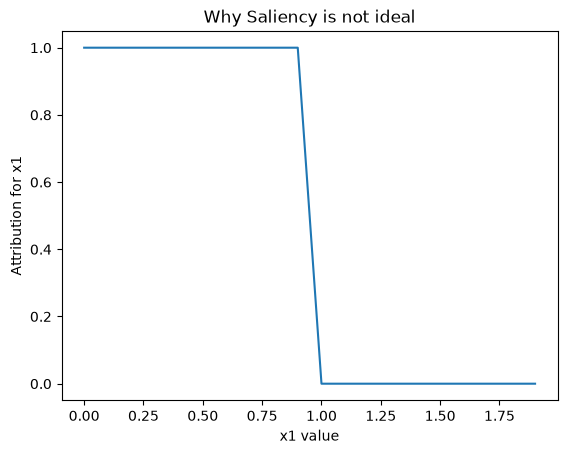

In [7]:
xs = []
attribs = []

for step in range(20):
    x1 = step / 10
    x2 = 100

    prediction = model(torch.tensor([x1, x2]))
    attribution = attribute_with_saliency(model, torch.tensor([x1, x2]))

    print(f"x_1: {x1}, prediction: {prediction}, attribution: {attribution}")

    xs.append(x1)
    attribs.append(attribution[0].item())

plt.plot(xs, attribs)
plt.xlabel("x1 value")
plt.ylabel("Attribution for x1")
plt.title("Why Saliency is not ideal")

**Sanity check**: Explain why this is... kinda bad.

**Sanity check 2**: Explain why we didn't even show you how the Input x Gradient would work here. (Hint: it wouldn't)

### Integrated Gradients

The previous methods kinda tried to create attributions by showing how to "change mind" of the model (like, locally). This tends to kinda break sometimes though (as we've seen), so the plan is to use something else.

**Integrated Gradients (IG)** is something else. It still relies on gradients, but tries to explain the prediction in a way that does not fall for such simple tricks. We will need to establish a baseline **b**, which has semantics of a "neutral" input (for example: black image in computer vision).

After establishing the baseline, we will linearly interpolate inputs between the baseline and the input tensor and sum up gradients for each one of the features along the way.

Formally, this interpolation for feature $x_i$ would look like this:

$$ \int_{\alpha=0}^1
\frac{\partial f( (1 - \alpha) \cdot b + \alpha \cdot x )}{\partial x_i} d\alpha $$

In practice, IG scales every attribution a bit:

$$\mathrm{IG}_i=(x_i-b_i)\int_{\alpha=0}^1
\frac{\partial f( (1 - \alpha) \cdot b + \alpha \cdot x )}{\partial x_i} d\alpha.$$


x_1: 0.0, prediction: 0.0, attribution: tensor([[0., 0.]])
x_1: 0.1, prediction: 0.10000002384185791, attribution: tensor([[0.1000, 0.0000]])
x_1: 0.2, prediction: 0.19999998807907104, attribution: tensor([[0.2000, 0.0000]])
x_1: 0.3, prediction: 0.30000001192092896, attribution: tensor([[0.3000, 0.0000]])
x_1: 0.4, prediction: 0.3999999761581421, attribution: tensor([[0.4000, 0.0000]])
x_1: 0.5, prediction: 0.5, attribution: tensor([[0.5000, 0.0000]])
x_1: 0.6, prediction: 0.6000000238418579, attribution: tensor([[0.6000, 0.0000]])
x_1: 0.7, prediction: 0.699999988079071, attribution: tensor([[0.7000, 0.0000]])
x_1: 0.8, prediction: 0.800000011920929, attribution: tensor([[0.8000, 0.0000]])
x_1: 0.9, prediction: 0.8999999761581421, attribution: tensor([[0.9000, 0.0000]])
x_1: 1.0, prediction: 1.0, attribution: tensor([[1., 0.]])
x_1: 1.1, prediction: 1.0, attribution: tensor([[0.9920, 0.0000]])
x_1: 1.2, prediction: 1.0, attribution: tensor([[1.0075, 0.0000]])
x_1: 1.3, prediction: 1.

Text(0.5, 1.0, 'Why Integrated Gradients is cool')

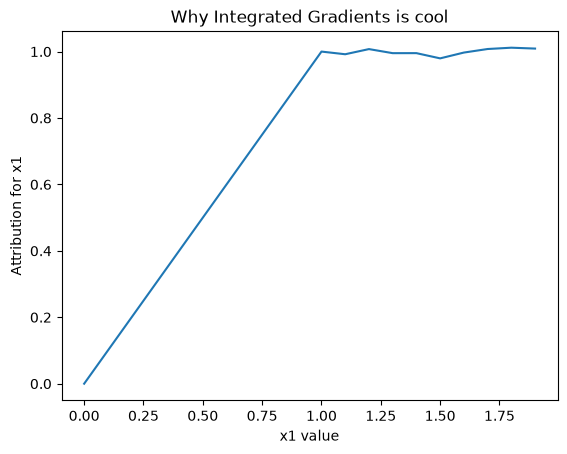

In [8]:
# While implementing this yourself is a good exercise (do it if you want to make sure you understand it!), we'll use captum library.

model = TrollingModel()

ig = captum.attr.IntegratedGradients(
    model
)

xs = []
attribs = []

for step in range(20):
    x1 = step / 10
    x2 = 100

    prediction = model(torch.tensor([x1, x2]))

    baseline = torch.tensor([[0, 0]]).float()
    #We add an additional dimension here because Captum loves to batch stuff, and otherwise this would break itself
    attribution = ig.attribute(torch.tensor([[x1, x2]]), baseline)

    print(f"x_1: {x1}, prediction: {prediction}, attribution: {attribution}")

    xs.append(x1)
    attribs.append(attribution[0][0].item())

plt.plot(xs, attribs)
plt.xlabel("x1 value")
plt.ylabel("Attribution for x1")
plt.title("Why Integrated Gradients is cool")


### Shapley Values

Shapley Values is another cool attribution method. Here, we aggregate all possible situations under which a certain feature could've altered neural network's prediction.

A little bit more technically: we take all **coalitions** out of features (so we mask some of them, setting them to some kind of baseline value (e.g. 0, but that depends on your network, similarly as in IG) and we check how much a given feature "helped" convince the model to increase its prediction. Yes, it's computationally terrible. Yes, that's a problem.

If you don't like vibe-explanations, here is an equation. To explain attribution $a_i$ for function $f(x)$, you may wanna calculate something like this:

$$
a_i = \sum_{\mathcal{C} \subseteq [N] \setminus \{ i \} } (f(\mathcal{C} \cup \{ i \}) - f(\mathcal{C}))
$$

where:
* $\mathcal{C}$ is called a *coalition*
* $N$ is number of features
* $[N]$ means a set $[N] = \{0, \; 1, \; 2, \dots, \; N-1\}$ (it's a notation thing you may or may not be used to)
* we call $f(\mathcal{C} \cup \{ i \}) - f(\mathcal{C})$ a **marginal contribution**

Buuut, **this is not what Shapley Values are**. We also weight the marginal contributions here:

$$
a_i = \frac{1}{N} \sum_{\mathcal{C} \subseteq [N] \setminus \{ i \} } \frac{1}{\binom{N-1}{|\mathcal{C}|}} (f(\mathcal{C} \cup \{ i \}) - f(\mathcal{C}))
$$

This is some probabilistic assumption. Either way, this thing's kinda cool. And you do not need to implement it, because, uhhh, captum.

In [9]:
model = TrollingModel()
shapley = captum.attr.ShapleyValues(
    model
)

inputs = torch.tensor([[1, 0]]).float()
baseline = torch.tensor([[0, 0]]).float() # We need baseline to mask features not-in-coalition
attribution = shapley.attribute(inputs, baseline)

print(attribution)

tensor([[1., 0.]])


### Shapley Value Sampling

This is a variation of shapley which, basically, samples different coalitions (this is a little bit of oversimplification, you can look it up here: https://captum.ai/api/shapley_value_sampling.html)

This allows it to, like, at least give some output in a finite time (in more complex cases). Which is pretty desirable when you're making some XAI method ;D

In [10]:
model = TrollingModel()
svs = captum.attr.ShapleyValueSampling(model)

inputs = torch.tensor([[1, 0]]).float()
baseline = torch.tensor([[0, 0]]).float() # We need baseline to mask features not-in-coalition
attribution = svs.attribute(inputs, baseline)

print(attribution)

tensor([[1., 0.]])


## What happens when you use more inputs for Shapley?

Let's make a funny model that just sums all the elements and see how the Shapley slows down the more features you give it.

In [12]:
class ToyModelThatCanTakeInputOfDifferentShapes(torch.nn.Module):
    def __init__(self):
        super(ToyModelThatCanTakeInputOfDifferentShapes, self).__init__()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sum(x, dim=-1)

model = ToyModelThatCanTakeInputOfDifferentShapes()
shapley = captum.attr.ShapleyValues(model)

for i in range(1, 8):
    x = torch.ones((1, i))
    baseline = torch.zeros_like(x)
    print(i, 'features')
    %time attribution = shapley.attribute(x, baseline)
    print(attribution)

1 features
CPU times: user 2.47 ms, sys: 0 ns, total: 2.47 ms
Wall time: 2.21 ms
tensor([[1.]])
2 features
CPU times: user 2.26 ms, sys: 11 μs, total: 2.27 ms
Wall time: 2.13 ms
tensor([[1., 1.]])
3 features
CPU times: user 8.45 ms, sys: 977 μs, total: 9.43 ms
Wall time: 8.98 ms
tensor([[1., 1., 1.]])
4 features
CPU times: user 33.4 ms, sys: 0 ns, total: 33.4 ms
Wall time: 33.4 ms
tensor([[1., 1., 1., 1.]])
5 features
CPU times: user 143 ms, sys: 0 ns, total: 143 ms
Wall time: 143 ms
tensor([[1., 1., 1., 1., 1.]])
6 features
CPU times: user 1.31 s, sys: 6 μs, total: 1.31 s
Wall time: 1.31 s
tensor([[1., 1., 1., 1., 1., 1.]])
7 features
CPU times: user 8.05 s, sys: 133 μs, total: 8.05 s
Wall time: 8.05 s
tensor([[1., 1., 1., 1., 1., 1., 1.]])


## Bonus: WOMBAT

As you may have noticed, we didn't really try to troll Integrated Gradients here. IG however can be trolled, albeit it's a little bit more tricky.

In short, the weakness of IG lies in its strength, i.e. the fact that it interpolates over the inputs (from the baseline to the model's input). If this interpolation goes through regions where the model behaves weirdly, things can go bad.

This is actually discussed in literature, but one of our papers creates a graph neural network that somewhat uses this to mess with IG and studies what exactly is happening (https://arxiv.org/pdf/2610.00713).
